# Lab 4: Neural Forecasting of Time Series

Student: Lopatenko George (334771)  
Course: Machine Learning for Time Series (TSML)

This study compares two three-layer perceptrons, an LSTM and the three classical forecasting families retained from Lab 2. Each model is evaluated on the same ten non-overlapping test blocks at horizons 1, 7 and 14. The practical question is whether the additional flexibility of the neural models improves out-of-sample forecasts enough to justify their training cost.


In [1]:
import sys
import subprocess
import importlib.util
import os
from pathlib import Path

THREAD_VARIABLES = [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]
for variable in THREAD_VARIABLES:
    os.environ[variable] = "1"

LAB_DIR = Path.cwd()
if not (LAB_DIR / "M4_Lopatenko.ipynb").exists():
    candidates = [LAB_DIR / "tsml" / "lab-4", LAB_DIR.parent / "tsml" / "lab-4", Path("/content")]
    for candidate in candidates:
        if (candidate / "M4_Lopatenko.ipynb").exists():
            LAB_DIR = candidate
            break

REQUIRED_MODULES = ["numpy", "pandas", "torch", "statsmodels", "plotly", "kaleido", "prettytable"]
missing = [module for module in REQUIRED_MODULES if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])


In [2]:
import base64
import copy
import html
import json
import platform
import time
import warnings
from dataclasses import dataclass
from pathlib import Path
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import torch
from IPython.display import HTML, display
from plotly.subplots import make_subplots
from prettytable import PrettyTable
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from torch import nn

warnings.filterwarnings("ignore")

SEED = 42
HORIZONS = (1, 7, 14)
N_SPLITS = 10
MAX_TRAIN_WINDOWS = 384
VALIDATION_SHARE = 0.15
MAX_EPOCHS = 80
PATIENCE = 8
FIG_WIDTH, FIG_SCALE = 1400, 3

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
pio.templates.default = "plotly_white"

DATA_DIR = LAB_DIR / "data"
FIGURES_DIR = LAB_DIR / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

MODEL_COLORS = {
    "ReLU MLP": "#0072B2",
    "Sigmoid MLP": "#D55E00",
    "LSTM": "#009E73",
    "AutoReg": "#CC79A7",
    "ARIMA": "#E69F00",
    "Holt-Winters": "#56B4E9",
}
NEURAL_MODELS = ("ReLU MLP", "Sigmoid MLP", "LSTM")
CLASSICAL_MODELS = ("AutoReg", "ARIMA", "Holt-Winters")


def show_table(frame: pd.DataFrame, caption: str, precision: int = 4, max_width: int = 28) -> None:
    def fmt(value) -> str:
        if pd.isna(value):
            return "—"
        if isinstance(value, (float, np.floating)):
            return f"{value:.{precision}f}"
        return str(value)

    table = PrettyTable()
    table.title = caption
    table.field_names = [str(column) for column in frame.columns]
    table.align = "l"
    for field in table.field_names:
        table.max_width[field] = max_width
    for row in frame.itertuples(index=False, name=None):
        table.add_row([fmt(value) for value in row])
    print(table)


def show_and_save(
    fig: go.Figure,
    stem: str,
    alt_text: str,
    height: int = 850,
    top_margin: int = 120,
    bottom_margin: int = 90,
    legend_y: float = 1.02,
) -> None:
    fig.update_layout(
        template="plotly_white",
        width=FIG_WIDTH,
        height=height,
        margin=dict(l=80, r=40, t=top_margin, b=bottom_margin),
        title_y=0.98,
        title_yanchor="top",
        font=dict(size=15, color="#252525"),
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=legend_y,
            xanchor="left",
            x=0,
            bgcolor="rgba(255,255,255,0.85)",
        ),
    )
    png_path = FIGURES_DIR / f"{stem}.png"
    svg_path = FIGURES_DIR / f"{stem}.svg"
    fig.write_image(str(png_path), scale=FIG_SCALE, width=FIG_WIDTH, height=height)
    fig.write_image(str(svg_path), width=FIG_WIDTH, height=height)
    encoded = base64.b64encode(png_path.read_bytes()).decode("ascii")
    image = (
        f'<img src="data:image/png;base64,{encoded}" alt="{html.escape(alt_text)}" '
        'style="max-width:100%;height:auto;">'
    )
    display(HTML(image))


## 1. Series and forecasting context

### EU hourly electricity load

The last 720 hourly observations combine a slowly changing level with pronounced 24-hour and 168-hour rhythms. Demand responds to human activity, weather and the calendar, so recent lags carry real predictive structure. A two-day input window lets the neural models see two complete daily cycles while remaining small enough for repeated estimation.

### Normal ECG

The signal contains six normal 140-sample beats from the TensorFlow ECG dataset. Its repeated P–QRS–T morphology is highly structured, but the series is an artificial concatenation of separately segmented beats rather than one continuous clinical recording. One complete beat is therefore the natural context window. Percentage errors require particular care here because the normalized waveform repeatedly crosses zero.

### SPY adjusted close

The final 750 daily adjusted closing prices of SPY form a persistent, non-stationary price level. A good one-step forecast can arise from simply staying close to the latest observation; this should not be mistaken for predictability of daily returns. A 20-session window represents roughly one trading month and gives the neural models more recent context without claiming a fixed seasonal cycle.


In [3]:
@dataclass(frozen=True)
class SeriesData:
    key: str
    label: str
    values: np.ndarray
    index: np.ndarray
    unit: str
    window: int
    source: str


ENERGY_URL = "https://raw.githubusercontent.com/unit8co/darts/master/datasets/energy_dataset.csv"
ECG_URL = "https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv"


def download(url: str, destination: Path) -> Path:
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=120) as response, destination.open("wb") as output:
        output.write(response.read())
    return destination


def local_or_download(filename: str, url: str, alternatives: list[Path]) -> Path:
    for path in [DATA_DIR / filename, *alternatives]:
        if path.exists() and path.stat().st_size > 0:
            return path
    return download(url, DATA_DIR / filename)


def load_energy(n: int = 720) -> SeriesData:
    path = local_or_download(
        "energy_dataset.csv",
        ENERGY_URL,
        [
            LAB_DIR.parent / "lab-2" / "data" / "energy_dataset.csv",
            LAB_DIR.parent / "lab-1" / "data" / "energy_dataset.csv",
        ],
    )
    frame = pd.read_csv(path).dropna(subset=["total load actual"]).iloc[-n:]
    time_column = "time" if "time" in frame.columns else frame.columns[0]
    dates = pd.to_datetime(frame[time_column], utc=True, errors="coerce").to_numpy()
    values = frame["total load actual"].to_numpy(dtype=float)
    return SeriesData(
        "EU_Hourly_Load", "EU hourly load", values, dates, "MW", 48,
        "Darts energy_dataset.csv; ENTSO-E total load actual",
    )


def load_ecg(n_beats: int = 6) -> SeriesData:
    path = local_or_download(
        "ecg.csv",
        ECG_URL,
        [
            LAB_DIR.parent / "lab-2" / "data" / "ecg.csv",
            LAB_DIR.parent / "lab-1" / "data" / "ecg.csv",
        ],
    )
    frame = pd.read_csv(path, header=None)
    normal = frame[frame.iloc[:, -1] == 1].iloc[:n_beats, :-1].to_numpy(dtype=float)
    values = normal.ravel()
    return SeriesData(
        "ECG_TF_Normal", "Normal ECG", values, np.arange(len(values)),
        "normalized amplitude", 140, "TensorFlow ECG anomaly dataset; six normal beats",
    )


def load_spy(n: int = 750) -> SeriesData:
    candidates = [
        DATA_DIR / "SPY_AdjClose.csv",
        LAB_DIR.parent / "lab-2" / "data" / "SPY_AdjClose.csv",
        LAB_DIR.parent / "lab-1" / "data" / "SPY_AdjClose.csv",
    ]
    for path in candidates:
        if path.exists() and path.stat().st_size > 0:
            frame = pd.read_csv(path, parse_dates=["Date"])
            price_column = "SPY" if "SPY" in frame.columns else "Adj Close"
            if price_column not in frame.columns:
                price_column = "Close"
            frame = frame[["Date", price_column]].dropna().iloc[-n:]
            return SeriesData(
                "SPY_AdjClose", "SPY adjusted close", frame[price_column].to_numpy(dtype=float),
                pd.DatetimeIndex(frame["Date"]).to_pydatetime(), "USD", 20,
                "Yahoo Finance adjusted daily close",
            )

    url = "https://query1.finance.yahoo.com/v8/finance/chart/SPY?interval=1d&range=5y"
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=60) as response:
        payload = json.loads(response.read().decode("utf-8"))
    result = payload["chart"]["result"][0]
    frame = pd.DataFrame({
        "Date": pd.to_datetime(result["timestamp"], unit="s"),
        "Adj Close": result["indicators"]["adjclose"][0]["adjclose"],
    }).dropna().iloc[-n:]
    frame.to_csv(DATA_DIR / "SPY_AdjClose.csv", index=False)
    return SeriesData(
        "SPY_AdjClose", "SPY adjusted close", frame["Adj Close"].to_numpy(dtype=float),
        pd.DatetimeIndex(frame["Date"]).to_pydatetime(), "USD", 20,
        "Yahoo Finance adjusted daily close",
    )


series = {item.key: item for item in [load_energy(), load_ecg(), load_spy()]}


The same three series from Lab 1 are retained throughout the comparison:

| Series | Observations | Sampling | Neural window | Structure used in the analysis |
|:--|--:|:--|--:|:--|
| EU hourly load | 720 | Hourly | 48 | Daily and weekly demand cycles |
| Normal ECG | 840 | Samples within six beats | 140 | Repeated 140-sample beat morphology |
| SPY adjusted close | 750 | Trading days | 20 | Persistent, stochastic price level |



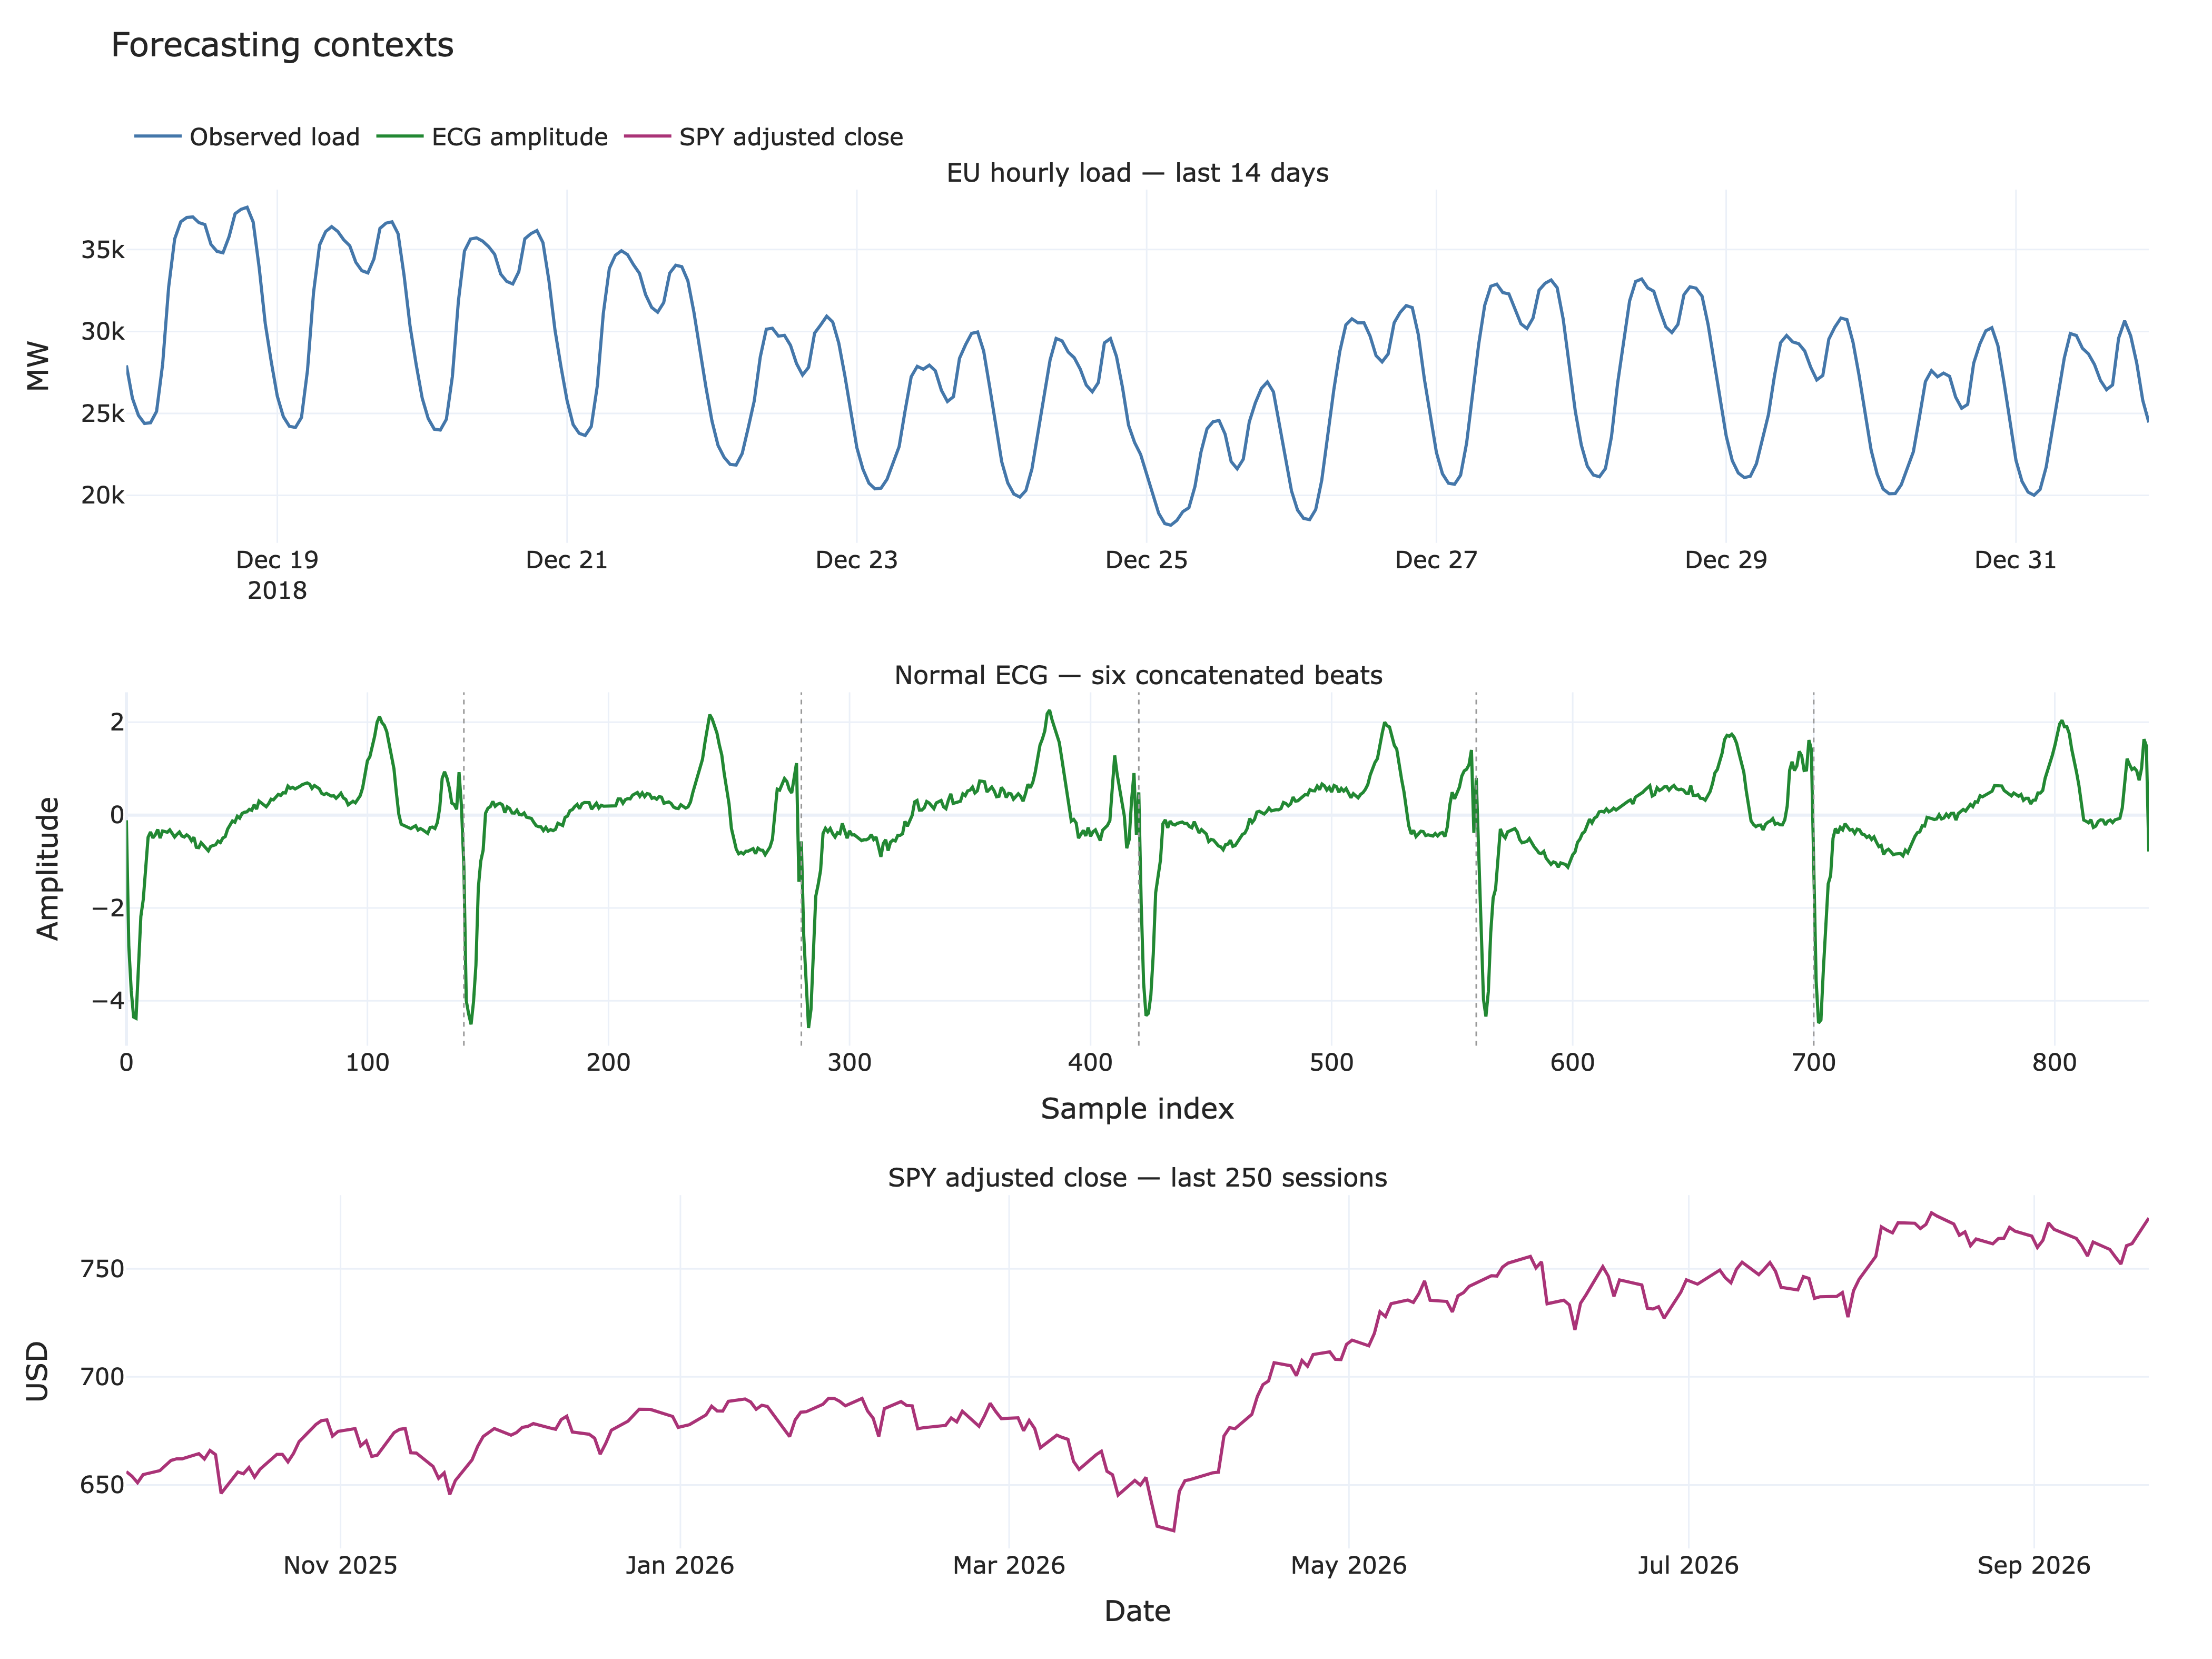

In [4]:
fig = make_subplots(
    rows=3,
    cols=1,
    shared_xaxes=False,
    vertical_spacing=0.11,
    subplot_titles=(
        "EU hourly load — last 14 days",
        "Normal ECG — six concatenated beats",
        "SPY adjusted close — last 250 sessions",
    ),
)

load = series["EU_Hourly_Load"]
fig.add_trace(
    go.Scatter(
        x=load.index[-24 * 14:],
        y=load.values[-24 * 14:],
        mode="lines",
        name="Observed load",
        line=dict(color="#4477AA", width=2),
    ),
    row=1,
    col=1,
)

ecg = series["ECG_TF_Normal"]
fig.add_trace(
    go.Scatter(
        x=ecg.index,
        y=ecg.values,
        mode="lines",
        name="ECG amplitude",
        line=dict(color="#228833", width=2),
    ),
    row=2,
    col=1,
)
for boundary in range(140, len(ecg.values), 140):
    fig.add_vline(x=boundary, line_width=1, line_dash="dot", line_color="#999999", row=2, col=1)

spy = series["SPY_AdjClose"]
fig.add_trace(
    go.Scatter(
        x=spy.index[-250:],
        y=spy.values[-250:],
        mode="lines",
        name="SPY adjusted close",
        line=dict(color="#AA3377", width=2),
    ),
    row=3,
    col=1,
)

fig.update_yaxes(title_text="MW", row=1, col=1)
fig.update_yaxes(title_text="Amplitude", row=2, col=1)
fig.update_yaxes(title_text="USD", row=3, col=1)
fig.update_xaxes(title_text="Sample index", row=2, col=1)
fig.update_xaxes(title_text="Date", row=3, col=1)
fig.update_layout(
    title="Forecasting contexts",
    hovermode="x unified",
)
show_and_save(
    fig,
    "series_overview",
    "Hourly load, normal ECG, and SPY adjusted-close overview",
    height=1050,
    bottom_margin=70,
)


Data sources: Darts/ENTSO-E energy data, TensorFlow ECG anomaly data, and Yahoo Finance SPY adjusted close.

The load trace has a stable daily cadence but visibly different peak heights, so a model must preserve periodicity without assuming that every day is identical. The ECG panel shows why a full-beat window is meaningful: the sharp QRS complex and the smoother surrounding waves recur, while the dotted boundaries remind us that the six rows were concatenated. SPY is smooth in level because consecutive closing prices are close; that persistence creates a strong forecasting baseline even when price changes themselves are difficult to anticipate.


## 2. Experimental design

For a horizon $h$, the last $10h$ observations are divided into ten adjacent blocks of length $h$. At each origin the model is fitted only to the prefix that would have been available at that time, then asked to forecast the next block recursively. This produces ten genuinely non-overlapping test segments for each of $h\in\{1,7,14\}$.

The neural models use a chronological validation tail rather than random shuffling. Scaling parameters are estimated from the observed prefix and every recursive forecast is made without seeing future values. The reported runtime contains preprocessing, fitting and forecasting; data loading and figure rendering are excluded. Numerical libraries are limited to one CPU thread, but the absolute seconds still depend on the processor and library versions.

MAPE is retained because it is the required metric:

$$\operatorname{MAPE}=\frac{100}{m}\sum_{t=1}^{m}\left|\frac{y_t-\hat y_t}{y_t}\right|.$$

It is readily interpretable for positive load and prices. For the normalized ECG, however, values close to zero make the ratio unstable: a small absolute miss can become a very large percentage error. ECG conclusions therefore use the distribution across all ten blocks rather than a single mean and are checked against absolute error as a diagnostic.


In [5]:
def test_origins(n: int, horizon: int, n_splits: int = N_SPLITS) -> list[int]:
    first = n - n_splits * horizon
    return [first + split * horizon for split in range(n_splits)]


The resulting test blocks are fixed by the series lengths:

| Series | Horizon | First test block | Last test block | Blocks |
|:--|--:|:--:|:--:|--:|
| EU hourly load | 1 | $[710,711)$ | $[719,720)$ | 10 |
| EU hourly load | 7 | $[650,657)$ | $[713,720)$ | 10 |
| EU hourly load | 14 | $[580,594)$ | $[706,720)$ | 10 |
| Normal ECG | 1 | $[830,831)$ | $[839,840)$ | 10 |
| Normal ECG | 7 | $[770,777)$ | $[833,840)$ | 10 |
| Normal ECG | 14 | $[700,714)$ | $[826,840)$ | 10 |
| SPY adjusted close | 1 | $[740,741)$ | $[749,750)$ | 10 |
| SPY adjusted close | 7 | $[680,687)$ | $[743,750)$ | 10 |
| SPY adjusted close | 14 | $[610,624)$ | $[736,750)$ | 10 |

The earliest origin changes with the horizon, which is intentional: every horizon consumes exactly ten complete blocks at the end of the same series. Comparisons between models at a fixed series and horizon are therefore paired block by block. Comparisons between different horizons describe different forecast tasks and should not be treated as paired observations.


In [6]:
denominator_rows = []
for item in series.values():
    longest_test_tail = item.values[-N_SPLITS * max(HORIZONS):]
    absolute = np.abs(longest_test_tail)
    denominator_rows.append({
        "Series": item.label,
        "Minimum |target|": absolute.min(),
        "Median |target|": np.median(absolute),
        "Minimum / median": absolute.min() / np.median(absolute),
    })

show_table(
    pd.DataFrame(denominator_rows),
    "MAPE denominator diagnostic over the longest test tail",
    precision=6,
    max_width=27,
)


+----------------------------------------------------------------------------+
|           MAPE denominator diagnostic over the longest test tail           |
+--------------------+------------------+-----------------+------------------+
| Series             | Minimum |target| | Median |target| | Minimum / median |
+--------------------+------------------+-----------------+------------------+
| EU hourly load     | 18522.000000     | 27935.000000    | 0.663039         |
| Normal ECG         | 0.006754         | 0.444072        | 0.015210         |
| SPY adjusted close | 628.784668       | 738.772491      | 0.851121         |
+--------------------+------------------+-----------------+------------------+


The smallest load and SPY targets remain at least two thirds of their respective median magnitudes. The smallest ECG magnitude is only about 1.5% of its median, so its percentage loss can be dominated by a few samples around zero. This is a property of the metric applied to a centered waveform, not evidence that the corresponding voltage error is hundreds of times the signal amplitude.


## 3. Models and hyperparameters

Both perceptrons have three trainable layers: two hidden layers with either ReLU or sigmoid activation, followed by a linear output layer. The linear head is important because none of the target series is confined to $[0,1]$. The LSTM reads the same window sequentially and maps its final hidden state to a one-step forecast.

The architecture is deliberately compact and fixed before the test runs. A larger model search on only a few hundred windows would be easy to overfit and would make the comparison less transparent. Adam is used throughout; early stopping restores the state with the lowest chronological validation loss.


The fixed model specification is compact enough to state directly:

| Model | Architecture | Optimizer | Purpose in the comparison |
|:--|:--|:--|:--|
| ReLU MLP | window → 32 ReLU → 16 ReLU → 1 linear | Adam, $lr=0.010$, weight decay $10^{-4}$ | Nonlinear baseline with piecewise-linear hidden units |
| Sigmoid MLP | window → 32 sigmoid → 16 sigmoid → 1 linear | Adam, $lr=0.010$, weight decay $10^{-4}$ | Same capacity as the ReLU model, changing only the activation |
| LSTM | one-layer LSTM(16) → 1 linear | Adam, $lr=0.005$, weight decay $10^{-4}$ | Recurrent summary of the ordered input window |

The input window follows the characteristic time scale of each series:

| Series | Window | Interpretation |
|:--|--:|:--|
| EU hourly load | 48 | Two daily cycles; also the lag span selected for AutoReg in Lab 2 |
| Normal ECG | 140 | One complete segmented heartbeat; the same span used in Lab 2 |
| SPY adjusted close | 20 | Approximately one trading month of recent price context |

Training is identical across test origins apart from the available historical prefix:

| Choice | Value | Reason |
|:--|:--|:--|
| Objective | MSE on standardized one-step targets | Stable optimization; predictions are transformed back to original units |
| Validation | Last 15% of supervised windows | Preserves chronology and is not used for gradient updates |
| Training history | Most recent 384 windows | Bounds cost and gives more weight to the current regime |
| Stopping | At most 80 epochs, patience 8 | Restores the state with the lowest validation loss |
| Forecast strategy | Recursive one-step prediction | Uses the same architecture for all three horizons without future inputs |


The ReLU and sigmoid networks have identical widths, optimizer and training data; their difference is therefore attributable to the hidden activation rather than parameter count. The LSTM is smaller because recurrent weights are reused at every step and already provide substantial capacity. Restricting training to the most recent 384 windows is also a practical form of regime adaptation for SPY and prevents the repeated walk-forward experiment from turning into a hardware benchmark.

The three classical models reuse the parameters selected on the pre-test validation segment in Lab 2: AutoReg(48), ARIMA(3,1,0) and additive seasonal Holt–Winters(24) for load; AutoReg(140), ARIMA(3,1,1) and additive trend/seasonality(140) for ECG; AutoReg(2), ARIMA(1,0,1) and simple exponential smoothing for SPY. No Lab 4 test block is used to alter those choices.


In [7]:
class ThreeLayerMLP(nn.Module):
    def __init__(self, window: int, activation: str):
        super().__init__()
        activation_layer = nn.ReLU if activation == "relu" else nn.Sigmoid
        self.network = nn.Sequential(
            nn.Linear(window, 32),
            activation_layer(),
            nn.Linear(32, 16),
            activation_layer(),
            nn.Linear(16, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x).squeeze(-1)


class LSTMForecaster(nn.Module):
    def __init__(self, hidden_size: int = 16):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        sequence, _ = self.lstm(x.unsqueeze(-1))
        return self.output(sequence[:, -1]).squeeze(-1)


def supervised_windows(values: np.ndarray, window: int) -> tuple[np.ndarray, np.ndarray]:
    x = np.array([values[end - window:end] for end in range(window, len(values))], dtype=np.float32)
    y = np.array(values[window:], dtype=np.float32)
    return x, y


def build_neural_model(name: str, window: int) -> tuple[nn.Module, float]:
    if name == "ReLU MLP":
        return ThreeLayerMLP(window, "relu"), 0.010
    if name == "Sigmoid MLP":
        return ThreeLayerMLP(window, "sigmoid"), 0.010
    return LSTMForecaster(hidden_size=16), 0.005


def neural_forecast(
    train: np.ndarray,
    horizon: int,
    window: int,
    model_name: str,
    seed: int,
) -> tuple[np.ndarray, float, float, int]:
    fit_start = time.perf_counter()
    torch.manual_seed(seed)

    center = float(np.mean(train))
    scale = float(np.std(train))
    if scale < 1e-12:
        scale = 1.0
    normalized = (np.asarray(train, dtype=float) - center) / scale
    x, y = supervised_windows(normalized, window)
    x, y = x[-MAX_TRAIN_WINDOWS:], y[-MAX_TRAIN_WINDOWS:]

    validation_size = max(1, int(np.ceil(len(x) * VALIDATION_SHARE)))
    x_train = torch.from_numpy(x[:-validation_size])
    y_train = torch.from_numpy(y[:-validation_size])
    x_valid = torch.from_numpy(x[-validation_size:])
    y_valid = torch.from_numpy(y[-validation_size:])

    model, learning_rate = build_neural_model(model_name, window)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    loss_function = nn.MSELoss()

    best_loss = np.inf
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    epochs_run = 0

    for epoch in range(MAX_EPOCHS):
        model.train()
        optimizer.zero_grad()
        loss = loss_function(model(x_train), y_train)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            validation_loss = float(loss_function(model(x_valid), y_valid))

        epochs_run = epoch + 1
        if validation_loss < best_loss - 1e-6:
            best_loss = validation_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                break

    model.load_state_dict(best_state)
    fit_seconds = time.perf_counter() - fit_start

    forecast_start = time.perf_counter()
    history = normalized.tolist()
    predictions = []
    model.eval()
    with torch.no_grad():
        for _ in range(horizon):
            model_input = torch.tensor(history[-window:], dtype=torch.float32).unsqueeze(0)
            next_value = float(model(model_input).item())
            history.append(next_value)
            predictions.append(center + scale * next_value)
    forecast_seconds = time.perf_counter() - forecast_start
    return np.asarray(predictions), fit_seconds, forecast_seconds, epochs_run


At each origin, the available prefix is converted to lagged windows. The newest 15% is reserved for validation, the best epoch is restored, and recursive prediction begins only after training is complete. No hidden state or fitted scaler crosses from one test origin to another.


In [8]:
CLASSICAL_CONFIG = {
    "EU_Hourly_Load": {
        "AutoReg": {"lags": 48},
        "ARIMA": {"order": (3, 1, 0)},
        "Holt-Winters": {"trend": None, "damped_trend": False, "seasonal": "add", "seasonal_periods": 24},
    },
    "ECG_TF_Normal": {
        "AutoReg": {"lags": 140},
        "ARIMA": {"order": (3, 1, 1)},
        "Holt-Winters": {"trend": "add", "damped_trend": False, "seasonal": "add", "seasonal_periods": 140},
    },
    "SPY_AdjClose": {
        "AutoReg": {"lags": 2},
        "ARIMA": {"order": (1, 0, 1)},
        "Holt-Winters": {"trend": None, "damped_trend": False, "seasonal": None, "seasonal_periods": None},
    },
}


def classical_forecast(
    train: np.ndarray,
    horizon: int,
    model_name: str,
    config: dict,
) -> tuple[np.ndarray, float, float]:
    fit_start = time.perf_counter()
    if model_name == "AutoReg":
        fitted = AutoReg(train, lags=config["lags"], trend="ct").fit()
    elif model_name == "ARIMA":
        order = config["order"]
        trend = "c" if order[1] == 0 else "t" if order[1] == 1 else "n"
        fitted = ARIMA(
            train,
            order=order,
            trend=trend,
            enforce_stationarity=False,
            enforce_invertibility=False,
        ).fit()
    else:
        fitted = ExponentialSmoothing(
            train,
            trend=config["trend"],
            damped_trend=config["damped_trend"],
            seasonal=config["seasonal"],
            seasonal_periods=config["seasonal_periods"],
            initialization_method="estimated",
        ).fit(optimized=True, use_brute=False)
    fit_seconds = time.perf_counter() - fit_start

    forecast_start = time.perf_counter()
    if model_name == "AutoReg":
        prediction = np.asarray(fitted.predict(len(train), len(train) + horizon - 1), dtype=float)
    else:
        prediction = np.asarray(fitted.forecast(horizon), dtype=float)
    forecast_seconds = time.perf_counter() - forecast_start
    return prediction, fit_seconds, forecast_seconds


def mape(actual: np.ndarray, predicted: np.ndarray) -> float:
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    nonzero = np.abs(actual) > 1e-12
    return float(100 * np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])))


def mae(actual: np.ndarray, predicted: np.ndarray) -> float:
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(predicted))))


## 4. Repeated walk-forward evaluation

The following cell performs 540 fits: three neural and three classical models, three series, three horizons and ten origins. A separate model is estimated at every origin. This is more expensive than fitting once and slicing ten forecasts, but it preserves the information set available at each forecast date and gives comparable timing measurements.


In [9]:
rows = []
forecast_rows = []
run_seed = SEED

experiment_start = time.perf_counter()
for item in series.values():
    for horizon in HORIZONS:
        for split, origin in enumerate(test_origins(len(item.values), horizon), start=1):
            train = item.values[:origin]
            actual = item.values[origin:origin + horizon]

            for model_name in NEURAL_MODELS:
                run_seed += 1
                predicted, fit_seconds, forecast_seconds, epochs = neural_forecast(
                    train, horizon, item.window, model_name, run_seed
                )
                rows.append({
                    "series": item.key,
                    "series_label": item.label,
                    "horizon": horizon,
                    "split": split,
                    "origin": origin,
                    "family": "Neural",
                    "model": model_name,
                    "seed": run_seed,
                    "mape": mape(actual, predicted),
                    "mae": mae(actual, predicted),
                    "fit_seconds": fit_seconds,
                    "forecast_seconds": forecast_seconds,
                    "total_seconds": fit_seconds + forecast_seconds,
                    "epochs": epochs,
                })
                for step, (observed, estimate) in enumerate(zip(actual, predicted), start=1):
                    forecast_rows.append({
                        "series": item.key,
                        "horizon": horizon,
                        "split": split,
                        "model": model_name,
                        "step": step,
                        "actual": observed,
                        "predicted": estimate,
                    })

            for model_name in CLASSICAL_MODELS:
                predicted, fit_seconds, forecast_seconds = classical_forecast(
                    train, horizon, model_name, CLASSICAL_CONFIG[item.key][model_name]
                )
                rows.append({
                    "series": item.key,
                    "series_label": item.label,
                    "horizon": horizon,
                    "split": split,
                    "origin": origin,
                    "family": "Classical",
                    "model": model_name,
                    "mape": mape(actual, predicted),
                    "mae": mae(actual, predicted),
                    "fit_seconds": fit_seconds,
                    "forecast_seconds": forecast_seconds,
                    "total_seconds": fit_seconds + forecast_seconds,
                    "epochs": np.nan,
                })
                for step, (observed, estimate) in enumerate(zip(actual, predicted), start=1):
                    forecast_rows.append({
                        "series": item.key,
                        "horizon": horizon,
                        "split": split,
                        "model": model_name,
                        "step": step,
                        "actual": observed,
                        "predicted": estimate,
                    })

results = pd.DataFrame(rows)
forecasts = pd.DataFrame(forecast_rows)
experiment_seconds = time.perf_counter() - experiment_start

results.to_csv(LAB_DIR / "forecast_results_raw.csv", index=False)
forecasts.to_csv(LAB_DIR / "forecast_paths.csv", index=False)

run_info = pd.DataFrame([
    {"Item": "Python", "Value": platform.python_version()},
    {"Item": "PyTorch", "Value": torch.__version__},
    {"Item": "Processor", "Value": platform.processor() or platform.machine()},
    {"Item": "Torch threads", "Value": torch.get_num_threads()},
    {"Item": "Neural device", "Value": "CPU"},
    {"Item": "Total measured experiment", "Value": f"{experiment_seconds:.2f} s"},
])
show_table(run_info, "Execution environment", precision=2, max_width=58)


+-------------------------------------+
|        Execution environment        |
+---------------------------+---------+
| Item                      | Value   |
+---------------------------+---------+
| Python                    | 3.14.7  |
| PyTorch                   | 2.11.0  |
| Processor                 | arm     |
| Torch threads             | 1       |
| Neural device             | CPU     |
| Total measured experiment | 81.22 s |
+---------------------------+---------+


The total above is the end-to-end model evaluation time on this machine. The per-model measurements below are more useful than the total because they separate algorithms and exclude notebook overhead such as drawing and encoding figures. Small timing differences should not be generalized across hardware, but order-of-magnitude differences are meaningful for this implementation.


## 5. Forecast accuracy


In [10]:
summary = (
    results.groupby(["series", "series_label", "horizon", "family", "model"], as_index=False)
    .agg(
        mean_mape=("mape", "mean"),
        median_mape=("mape", "median"),
        q1_mape=("mape", lambda values: values.quantile(0.25)),
        q3_mape=("mape", lambda values: values.quantile(0.75)),
        mean_mae=("mae", "mean"),
    )
)
summary["iqr_mape"] = summary["q3_mape"] - summary["q1_mape"]
summary.to_csv(LAB_DIR / "forecast_results_summary.csv", index=False)

for key, item in series.items():
    table = summary[summary["series"] == key][
        ["horizon", "family", "model", "mean_mape", "median_mape", "iqr_mape", "mean_mae"]
    ].rename(columns={
        "horizon": "h",
        "family": "Family",
        "model": "Model",
        "mean_mape": "Mean MAPE, %",
        "median_mape": "Median MAPE, %",
        "iqr_mape": "MAPE IQR, pp",
        "mean_mae": f"Mean MAE, {item.unit}",
    })
    show_table(table, f"{item.label}: accuracy across ten test blocks", precision=4, max_width=22)


+---------------------------------------------------------------------------------------------+
|                       EU hourly load: accuracy across ten test blocks                       |
+----+-----------+--------------+--------------+----------------+--------------+--------------+
| h  | Family    | Model        | Mean MAPE, % | Median MAPE, % | MAPE IQR, pp | Mean MAE, MW |
+----+-----------+--------------+--------------+----------------+--------------+--------------+
| 1  | Classical | ARIMA        | 2.9619       | 1.9725         | 2.2377       | 847.6264     |
| 1  | Classical | AutoReg      | 2.2977       | 1.9043         | 2.4916       | 646.3987     |
| 1  | Classical | Holt-Winters | 2.4873       | 1.7529         | 3.9984       | 696.0448     |
| 1  | Neural    | LSTM         | 4.8110       | 3.8707         | 3.9799       | 1348.8714    |
| 1  | Neural    | ReLU MLP     | 4.6659       | 4.9993         | 2.9103       | 1263.9484    |
| 1  | Neural    | Sigmoid MLP  | 7.4697

The mean summarizes total percentage loss across the ten blocks, while the median and IQR expose whether that mean is representative. The difference is substantial for ECG: at $h=14$, for example, Holt–Winters has 89.45% mean MAPE but only 28.08% median MAPE because a few near-zero targets dominate the mean. MAE is reported beside MAPE to show the error in the signal's native scale; it is diagnostic rather than a replacement for the required metric.



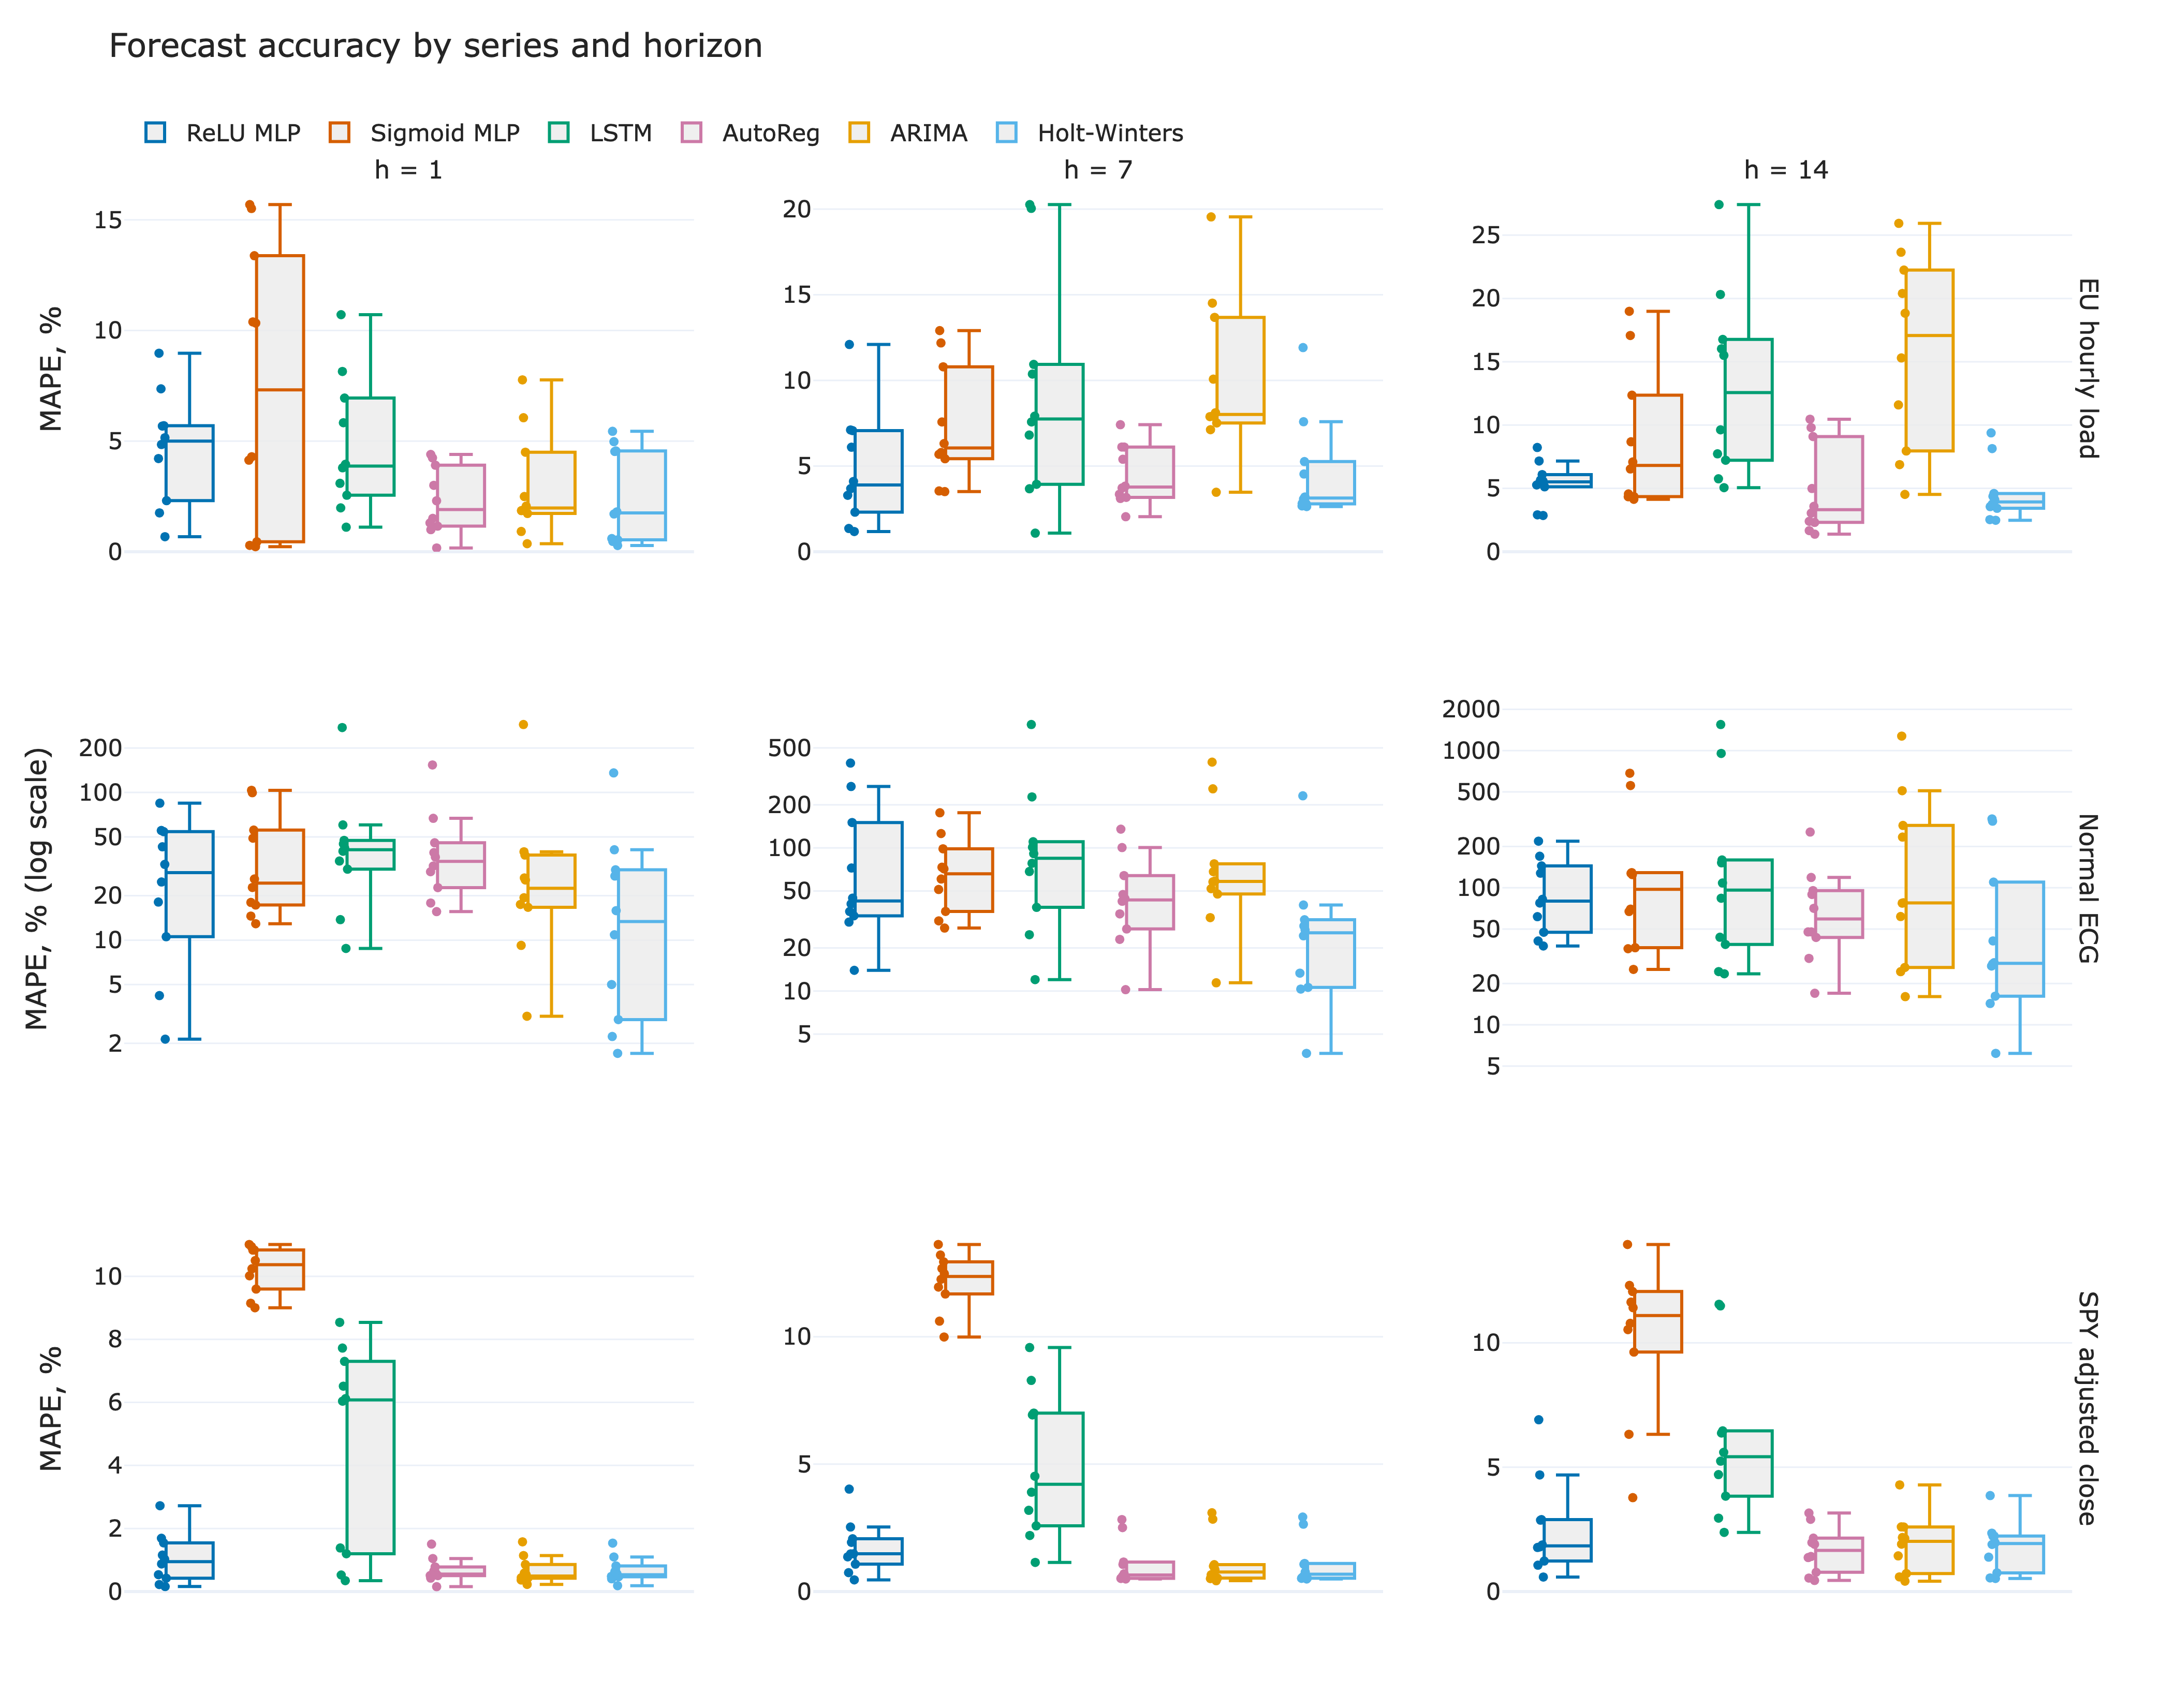

In [11]:
fig = make_subplots(
    rows=3,
    cols=3,
    shared_yaxes=False,
    horizontal_spacing=0.06,
    vertical_spacing=0.11,
    row_titles=[series[key].label for key in series],
    column_titles=[f"h = {h}" for h in HORIZONS],
)

model_order = [*NEURAL_MODELS, *CLASSICAL_MODELS]
for row, key in enumerate(series, start=1):
    for col, horizon in enumerate(HORIZONS, start=1):
        panel = results[(results["series"] == key) & (results["horizon"] == horizon)]
        for model_name in model_order:
            values = panel.loc[panel["model"] == model_name, "mape"]
            fig.add_trace(
                go.Box(
                    y=values,
                    name=model_name,
                    legendgroup=model_name,
                    marker=dict(color=MODEL_COLORS[model_name], size=6, opacity=1),
                    line=dict(color=MODEL_COLORS[model_name], width=2),
                    fillcolor="rgba(235,235,235,0.8)",
                    opacity=1,
                    width=0.52,
                    boxpoints="all",
                    jitter=0.22,
                    pointpos=-1.15,
                    showlegend=(row == 1 and col == 1),
                    hovertemplate=f"{model_name}<br>MAPE=%{{y:.3f}}%<extra></extra>",
                ),
                row=row,
                col=col,
            )
        if key == "ECG_TF_Normal":
            fig.update_yaxes(
                title_text="MAPE, % (log scale)" if col == 1 else None,
                type="log",
                tickvals=[2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000],
                ticktext=["2", "5", "10", "20", "50", "100", "200", "500", "1000", "2000"],
                row=row,
                col=col,
            )
        else:
            fig.update_yaxes(title_text="MAPE, %" if col == 1 else None, rangemode="tozero", row=row, col=col)
        fig.update_xaxes(showticklabels=False, row=row, col=col)

fig.update_layout(
    title="Forecast accuracy by series and horizon",
    boxmode="group",
)
show_and_save(
    fig,
    "mape_boxplots",
    "MAPE distributions by series, horizon, and model",
    height=1100,
    bottom_margin=75,
)


Each panel contains ten non-overlapping test blocks. Boxes show quartiles, dots show individual block MAPEs, and the ECG row uses a logarithmic scale.

The boxplots show three different regimes.

- **Load:** AutoReg is best at $h=1$ and $h=7$ with mean MAPE 2.30% and 4.42%; Holt–Winters is best at $h=14$ with 4.64%. ReLU MLP is the strongest neural model throughout (4.67%, 4.83%, 5.43%). It nearly closes the gap at $h=7$, but its error is still 9.1% higher than AutoReg and it never wins on mean MAPE.
- **ECG:** Holt–Winters leads at $h=1$ and $h=7$ (27.22% and 42.00% mean MAPE), while AutoReg leads at $h=14$ (81.56%). The neural winner changes from ReLU to sigmoid and back to ReLU, which is evidence against a stable neural advantage. The widely separated points explain why medians and MAE are more informative here than the mean alone.
- **SPY:** the classical forecasts form a tight low-error cluster. ARIMA is best at $h=1$ (0.661%), then AutoReg at $h=7$ and $h=14$ (1.091% and 1.662%). ReLU MLP is the only competitive neural variant, but its mean MAPE remains roughly 55–57% above the best classical model at every horizon. Sigmoid MLP stays near 10–12%, suggesting severe underfitting of the moving price level under this fixed architecture.

The result is therefore not “neural models are worse” in general. It is narrower: with the stated compact architectures, limited histories and recursive training protocol, the classical inductive biases match these three series better.


In [12]:
winner_rows = []
for key, item in series.items():
    for horizon in HORIZONS:
        panel = summary[(summary["series"] == key) & (summary["horizon"] == horizon)]
        neural = panel[panel["family"] == "Neural"].sort_values("mean_mape").iloc[0]
        classical = panel[panel["family"] == "Classical"].sort_values("mean_mape").iloc[0]
        winner_rows.append({
            "Series": item.label,
            "h": horizon,
            "Best neural": neural["model"],
            "Neural MAPE, %": neural["mean_mape"],
            "Best classical": classical["model"],
            "Classical MAPE, %": classical["mean_mape"],
            "Neural vs classical, %": 100 * (neural["mean_mape"] / classical["mean_mape"] - 1),
        })

winners = pd.DataFrame(winner_rows)
show_table(winners, "Best neural and classical model at each horizon", precision=3, max_width=23)


+----------------------------------------------------------------------------------------------------------------------+
|                                   Best neural and classical model at each horizon                                    |
+--------------------+----+-------------+----------------+----------------+-------------------+------------------------+
| Series             | h  | Best neural | Neural MAPE, % | Best classical | Classical MAPE, % | Neural vs classical, % |
+--------------------+----+-------------+----------------+----------------+-------------------+------------------------+
| EU hourly load     | 1  | ReLU MLP    | 4.666          | AutoReg        | 2.298             | 103.068                |
| EU hourly load     | 7  | ReLU MLP    | 4.829          | AutoReg        | 4.424             | 9.148                  |
| EU hourly load     | 14 | ReLU MLP    | 5.432          | Holt-Winters   | 4.636             | 17.180                 |
| Normal ECG         | 1  | ReLU

The final column is relative error, not percentage points: negative values mean that the best neural model reduced mean MAPE compared with the strongest classical baseline, while positive values mean that it was worse. Selecting one winner within each family keeps the table readable, but the full summaries above remain necessary because a small mean advantage can coexist with much greater dispersion.


## 6. Runtime in measured seconds


In [13]:
timing = (
    results.groupby(["series", "series_label", "family", "model"], as_index=False)
    .agg(
        median_fit_seconds=("fit_seconds", "median"),
        median_forecast_seconds=("forecast_seconds", "median"),
        median_total_seconds=("total_seconds", "median"),
        mean_total_seconds=("total_seconds", "mean"),
    )
)
timing.to_csv(LAB_DIR / "forecast_timing_summary.csv", index=False)

for key, item in series.items():
    table = timing[timing["series"] == key][
        ["family", "model", "median_fit_seconds", "median_forecast_seconds", "median_total_seconds"]
    ].rename(columns={
        "family": "Family",
        "model": "Model",
        "median_fit_seconds": "Median fit, s",
        "median_forecast_seconds": "Median forecast, s",
        "median_total_seconds": "Median total, s",
    })
    show_table(table, f"{item.label}: measured runtime per origin", precision=5, max_width=23)


+---------------------------------------------------------------------------------+
|                   EU hourly load: measured runtime per origin                   |
+-----------+--------------+---------------+--------------------+-----------------+
| Family    | Model        | Median fit, s | Median forecast, s | Median total, s |
+-----------+--------------+---------------+--------------------+-----------------+
| Classical | ARIMA        | 0.03108       | 0.00093            | 0.03205         |
| Classical | AutoReg      | 0.00191       | 0.00033            | 0.00222         |
| Classical | Holt-Winters | 0.02042       | 0.00068            | 0.02110         |
| Neural    | LSTM         | 0.62615       | 0.00188            | 0.62825         |
| Neural    | ReLU MLP     | 0.01139       | 0.00015            | 0.01150         |
| Neural    | Sigmoid MLP  | 0.01133       | 0.00015            | 0.01154         |
+-----------+--------------+---------------+--------------------+-----------


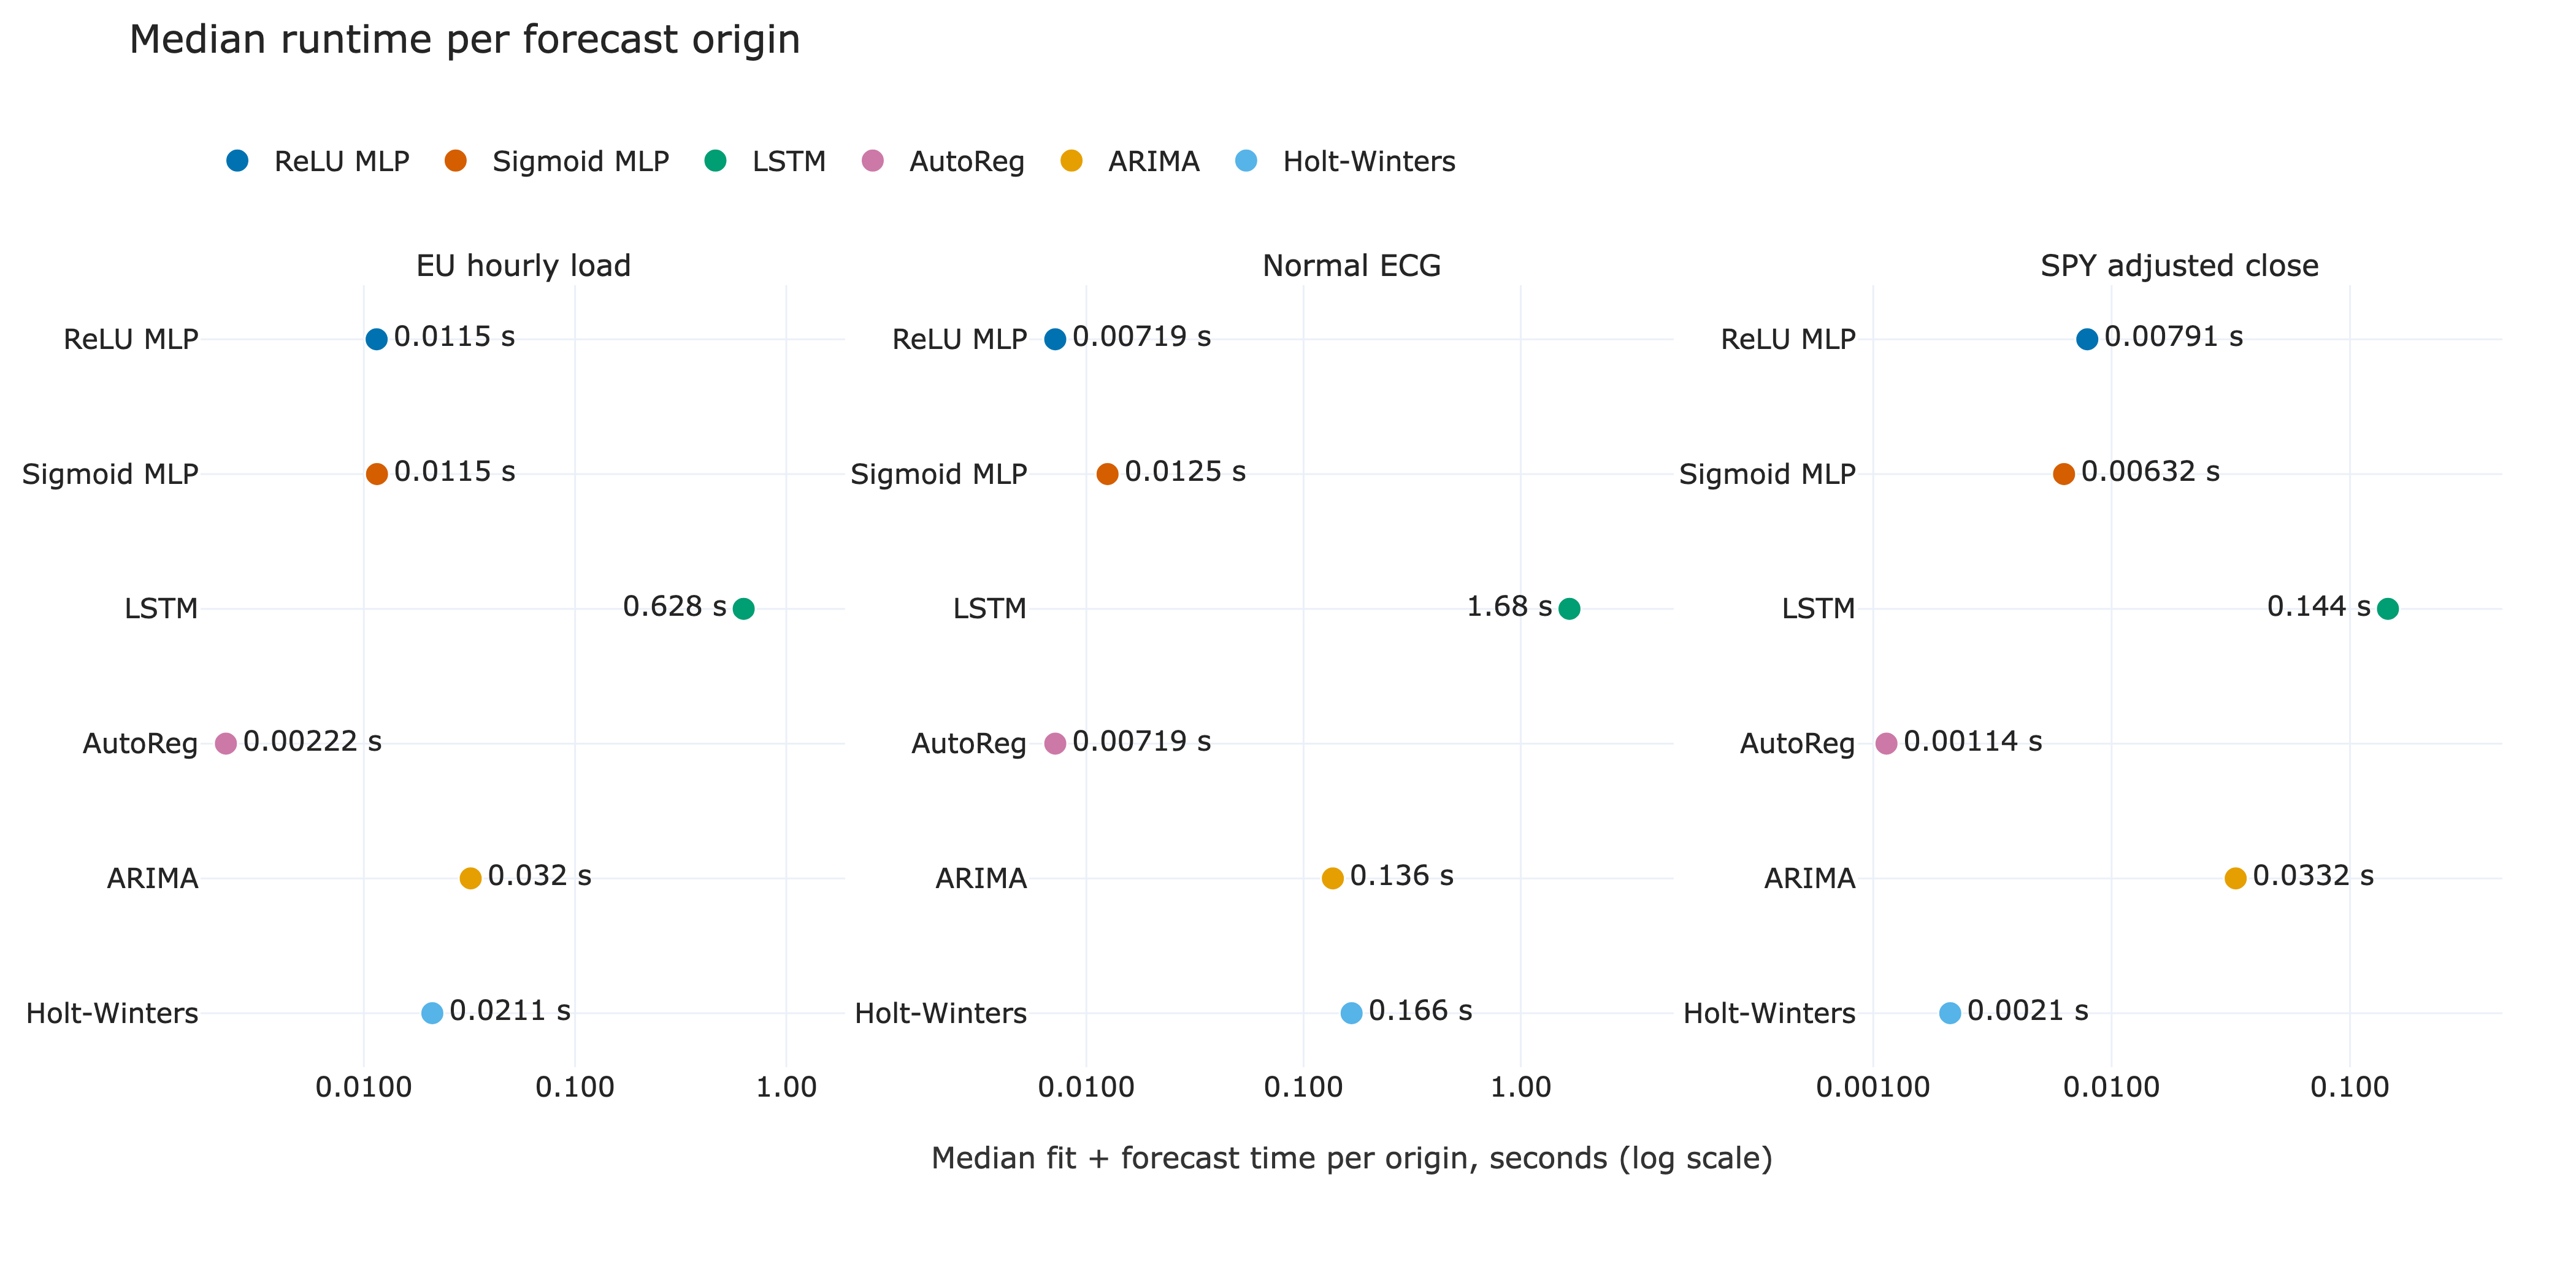

In [14]:
fig = make_subplots(
    rows=1,
    cols=3,
    horizontal_spacing=0.08,
    subplot_titles=[item.label for item in series.values()],
)

for col, key in enumerate(series, start=1):
    panel = timing[timing["series"] == key].set_index("model").loc[model_order].reset_index()
    slowest = panel.loc[panel["median_total_seconds"].idxmax(), "model"]
    for model_name in model_order:
        row = panel[panel["model"] == model_name].iloc[0]
        seconds = row["median_total_seconds"]
        fig.add_trace(
            go.Scatter(
                x=[seconds],
                y=[model_name],
                mode="markers+text",
                text=[f"{seconds:.3g} s"],
                textposition="middle left" if model_name == slowest else "middle right",
                marker=dict(size=13, color=MODEL_COLORS[model_name], line=dict(color="white", width=1)),
                name=model_name,
                legendgroup=model_name,
                showlegend=(col == 1),
                hovertemplate=f"{model_name}<br>median total=%{{x:.5f}} s<extra></extra>",
            ),
            row=1,
            col=col,
        )
    lower = np.log10(panel["median_total_seconds"].min()) - 0.12
    upper = np.log10(panel["median_total_seconds"].max()) + 0.48
    fig.update_xaxes(type="log", range=[lower, upper], dtick=1, tickformat=".3g", row=1, col=col)
    fig.update_yaxes(categoryorder="array", categoryarray=model_order[::-1], row=1, col=col)

fig.update_layout(title="Median runtime per forecast origin")
fig.add_annotation(
    x=0.5,
    y=-0.14,
    xref="paper",
    yref="paper",
    text="Median fit + forecast time per origin, seconds (log scale)",
    showarrow=False,
    font=dict(size=16, color="#333333"),
)
show_and_save(
    fig,
    "runtime_comparison",
    "Median runtime per forecast origin by series and model",
    height=700,
    top_margin=155,
    bottom_margin=120,
    legend_y=1.12,
)


Runtime is measured with `time.perf_counter`, with numerical libraries limited to one CPU thread. Each point is the median of 30 fits for one series and model.

The logarithmic axis is necessary because the fastest and slowest methods differ by orders of magnitude. The ReLU MLP is inexpensive—about 0.011 s per load origin and 0.007 s for both ECG and SPY—but AutoReg is still about five to six times faster on load and SPY. On ECG, ReLU MLP and AutoReg are effectively tied in runtime because fitting 140 autoregressive coefficients is no longer trivial.

The LSTM is the clear computational outlier: its median total time is about 0.60 s for load, 1.5 s for ECG and 0.13 s for SPY—roughly two orders of magnitude above AutoReg. Forecasting itself takes milliseconds; recurrent training dominates. Since the LSTM also has higher MAPE in every panel, this experiment provides no accuracy–cost case for choosing it.


## 7. Direct comparison with Lab 2

Lab 2 stored accuracy but did not record fit and forecast seconds. Its statsmodels results are used here to confirm that the same classical configurations and test blocks are being compared. All runtime values come from the common evaluation loop above, so timings from different machines or code paths are not mixed.


In [15]:
lab2_path = LAB_DIR.parent / "lab-2" / "forecast_mape_summary.csv"
if lab2_path.exists():
    lab2 = pd.read_csv(lab2_path)
    lab2 = lab2[(lab2["implementation"] == "statsmodels") & lab2["family"].isin(["AR", "ARIMA", "Holt-Winters"])].copy()
    lab2["model"] = lab2["family"].replace({"AR": "AutoReg"})
    current_classical = summary[summary["family"] == "Classical"][
        ["series", "horizon", "model", "mean_mape"]
    ]
    comparison = lab2.merge(current_classical, on=["series", "horizon", "model"], suffixes=("_lab2", "_lab4"))
    comparison["absolute difference, pp"] = np.abs(comparison["mean_mape_lab4"] - comparison["mean_mape_lab2"])
    consistency_check = (
        comparison.groupby(["series", "model"], as_index=False)
        .agg(max_abs_difference_pp=("absolute difference, pp", "max"))
        .merge(timing[["series", "model", "median_total_seconds"]], on=["series", "model"])
    )
    consistency_check["Series"] = consistency_check["series"].map({key: item.label for key, item in series.items()})
    consistency_check = consistency_check[
        ["Series", "model", "max_abs_difference_pp", "median_total_seconds"]
    ].rename(columns={
        "model": "Classical model",
        "max_abs_difference_pp": "Max |Lab 4 − Lab 2|, pp",
        "median_total_seconds": "New median runtime, s",
    })
    show_table(consistency_check, "Classical accuracy check and newly measured runtime", precision=6)
else:
    consistency_check = pd.DataFrame()
    print("Lab 2 summary file was not available for comparison.")


+----------------------------------------------------------------------------------------+
|                  Classical accuracy check and newly measured runtime                   |
+--------------------+-----------------+-------------------------+-----------------------+
| Series             | Classical model | Max |Lab 4 − Lab 2|, pp | New median runtime, s |
+--------------------+-----------------+-------------------------+-----------------------+
| Normal ECG         | ARIMA           | 0.000000                | 0.136421              |
| Normal ECG         | AutoReg         | 0.000000                | 0.007191              |
| Normal ECG         | Holt-Winters    | 0.000000                | 0.166463              |
| EU hourly load     | ARIMA           | 0.000000                | 0.032047              |
| EU hourly load     | AutoReg         | 0.000000                | 0.002223              |
| EU hourly load     | Holt-Winters    | 0.000000                | 0.021096              |

Every classical mean MAPE agrees with the Lab 2 CSV to the stored precision (maximum absolute difference 0.000000 percentage points). The comparison therefore uses the same data, origins and configurations. Runtime is measured here through the same wall-clock timer as the neural models.


## 8. What a 14-step forecast looks like

For each series, the figure uses the final test block, fixed independently of its error. To avoid an unreadable bundle of seven lines, it shows the lowest-mean-MAPE neural model and the lowest-mean-MAPE classical model for $h=14$, selected from all ten blocks. The selection uses repeated performance; the displayed block itself is not cherry-picked.



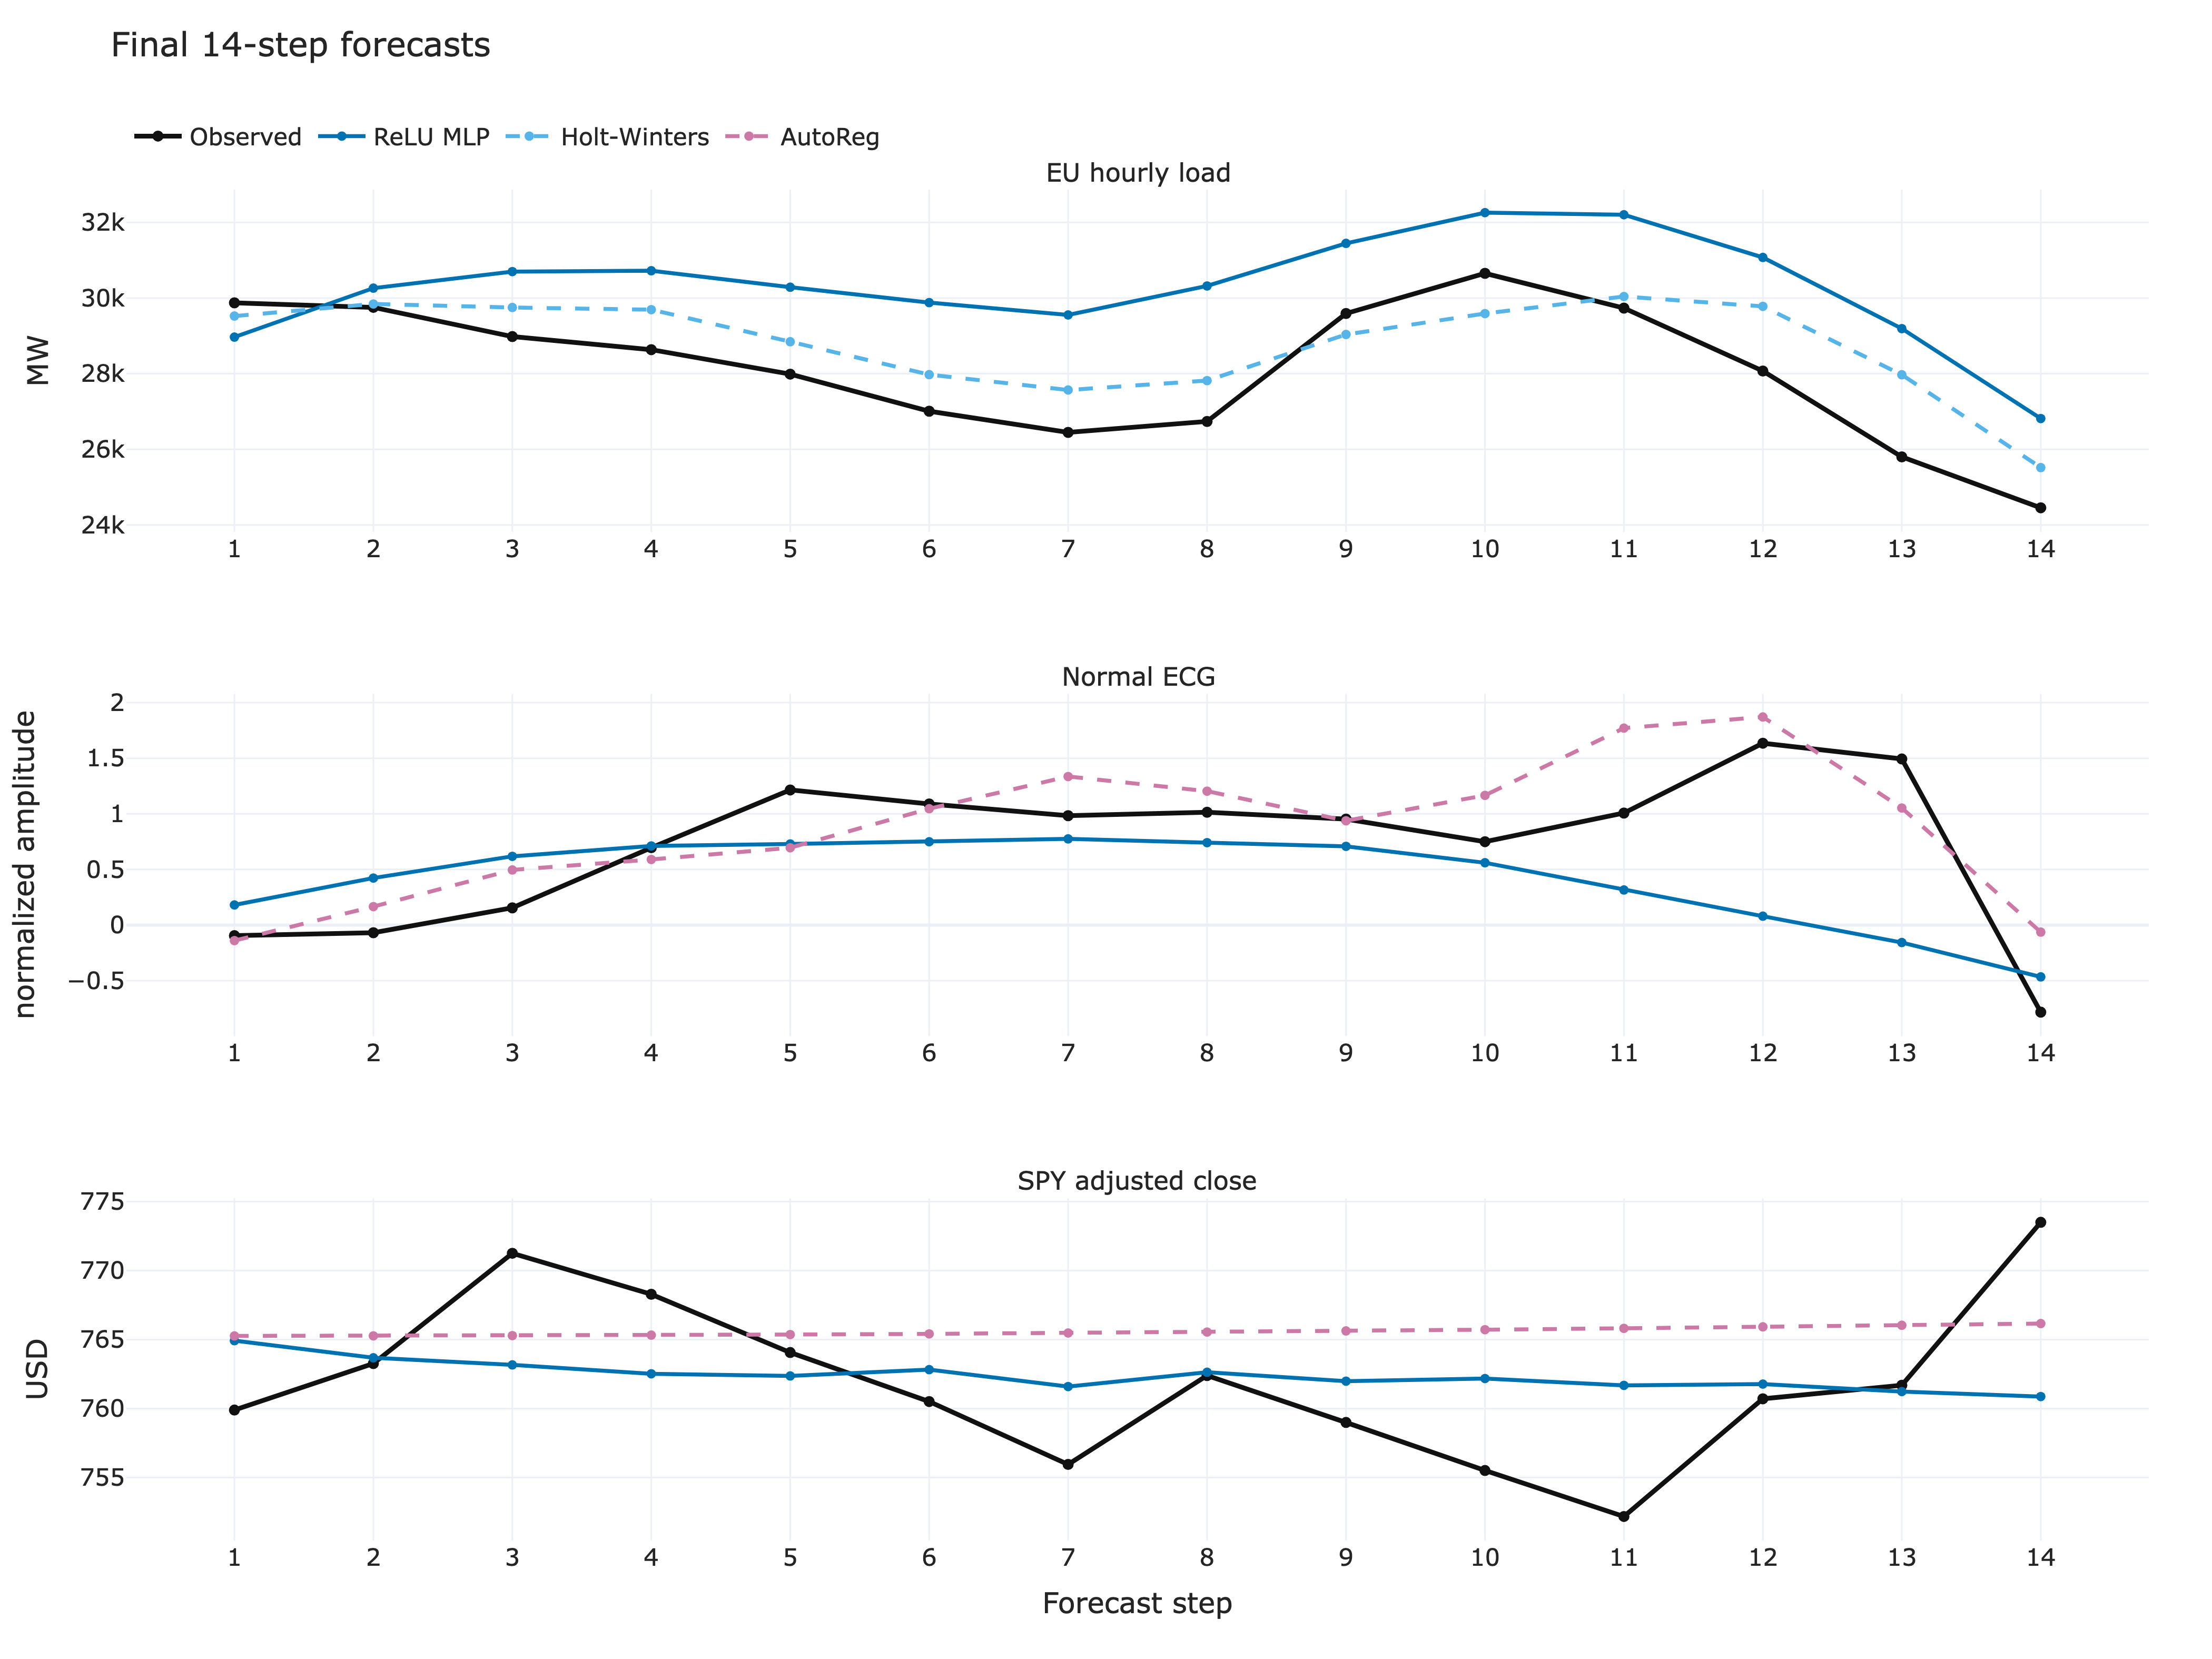

In [16]:
fig = make_subplots(
    rows=3,
    cols=1,
    shared_xaxes=False,
    vertical_spacing=0.12,
    subplot_titles=[item.label for item in series.values()],
)

example_models = {}
shown_in_legend = set()
for row, (key, item) in enumerate(series.items(), start=1):
    h14 = summary[(summary["series"] == key) & (summary["horizon"] == 14)]
    best_neural = h14[h14["family"] == "Neural"].sort_values("mean_mape").iloc[0]["model"]
    best_classical = h14[h14["family"] == "Classical"].sort_values("mean_mape").iloc[0]["model"]
    example_models[key] = (best_neural, best_classical)

    panel = forecasts[(forecasts["series"] == key) & (forecasts["horizon"] == 14) & (forecasts["split"] == 10)]
    actual = panel[panel["model"] == best_neural].sort_values("step")
    steps = actual["step"]
    fig.add_trace(
        go.Scatter(
            x=steps,
            y=actual["actual"],
            mode="lines+markers",
            name="Observed",
            legendgroup="Observed",
            line=dict(color="#111111", width=3),
            marker=dict(size=7),
            showlegend=(row == 1),
        ),
        row=row,
        col=1,
    )
    for model_name in [best_neural, best_classical]:
        path = panel[panel["model"] == model_name].sort_values("step")
        fig.add_trace(
            go.Scatter(
                x=path["step"],
                y=path["predicted"],
                mode="lines+markers",
                name=model_name,
                legendgroup=model_name,
                line=dict(
                    color=MODEL_COLORS[model_name],
                    width=2.5,
                    dash="dash" if model_name in CLASSICAL_MODELS else "solid",
                ),
                marker=dict(size=6),
                showlegend=model_name not in shown_in_legend,
            ),
            row=row,
            col=1,
        )
        shown_in_legend.add(model_name)
    fig.update_yaxes(title_text=item.unit, row=row, col=1)
    fig.update_xaxes(title_text="Forecast step" if row == 3 else None, dtick=1, row=row, col=1)

fig.update_layout(title="Final 14-step forecasts")
show_and_save(
    fig,
    "forecast_examples_h14",
    "Observed and forecast paths for final 14-step blocks",
    height=1050,
    bottom_margin=75,
)


The solid coloured line is the best neural model by mean 14-step MAPE, and the dashed line is the best classical model. The fixed final block is shown for each series.

The final blocks clarify the numerical comparison. For load, both ReLU MLP and Holt–Winters retain the broad intraday movement, but ReLU stays too high after the middle of the block; Holt–Winters follows the falling tail more closely. For ECG, AutoReg reproduces the rise toward the next waveform peak, whereas ReLU smooths that structure and crosses below zero too early. For SPY, both ReLU and AutoReg are essentially persistence forecasts: they cannot anticipate the observed swings, but AutoReg stays nearer the local level on average.

These are recursive paths, so later discrepancies include earlier prediction errors fed back as inputs. The plot is not used to choose a favorable split—the final block was fixed in advance—and should be read alongside all ten boxplot points.


## 9. Findings

ReLU MLP is the strongest neural method in eight of the nine series–horizon comparisons; sigmoid wins only for ECG at $h=7$. Even then, the best neural result does not beat the best classical result on mean MAPE. The smallest gap occurs for seven-hour load forecasts, where ReLU is 0.405 percentage points behind AutoReg. On SPY the gap is systematic rather than occasional: ReLU's mean percentage error is about 55–57% higher at every horizon.

The horizon effect is most visible in the recursive paths and in the widening block-to-block spread. It is not uniform, however. Holt–Winters remains stable for 14-hour load forecasting because its daily seasonal structure is useful, while every ECG mean is vulnerable to a few small denominators. This is why the ECG ranking is discussed with medians and MAE rather than from mean MAPE alone.

Runtime reinforces the accuracy result. The two MLPs are cheap enough to be plausible baselines, but the LSTM spends roughly 0.13–1.5 seconds per origin without an accuracy gain. More elaborate recurrent tuning could change that result, yet it would also enlarge the compute budget and the risk of selection overfitting on these short series.

## 10. Conclusion

This experiment does not identify a neural winner over the Lab 2 models. ReLU MLP is the most reliable neural architecture, winning eight of nine neural comparisons, but it remains behind the best classical model at all nine series–horizon combinations. The closest case is hourly load at $h=7$: 4.83% mean MAPE for ReLU versus 4.42% for AutoReg. The LSTM is both less accurate and one to three orders of magnitude slower than the compact alternatives, so recurrence adds no practical value under this sample size and tuning budget.

For these data, the defensible choices are AutoReg for load at $h=1$ and $h=7$, Holt–Winters for load at $h=14$; Holt–Winters for ECG at $h=1$ and $h=7$, AutoReg at $h=14$; and ARIMA for one-day SPY with AutoReg for the longer SPY horizons. This conclusion is conditional on the stated walk-forward design and mean MAPE. For a real ECG study, I would report MAE or another scale-stable waveform measure as a primary metric and treat percentage error only as a secondary diagnostic.
